# Catalogue Quality Challenge — Training and Submission

## Objective and protocol

Predict the probability that an offer contains a controlled catalogue corruption. The method
extracts product facts, estimates expected catalogue attributes, and combines consistency signals
with CatBoost.

**Model development and validation use only `train.csv`.** Five outer seller folds provide
out-of-fold predictions, and three inner seller folds prevent reference-feature leakage.
The prediction dataset is loaded only in the final inference section. No distributional exploration,
fitting, early stopping or parameter selection uses it.

All core functions are included. Run cells in order with `requirements-notebook.txt`.
Generated models, metrics and `submission.csv` are written to `outputs/catalogue_submission/`;
rerunning refreshes that notebook-owned output folder.

## 1. Load and validate training data

IDs identify rows and sellers define validation groups. Neither ID is a predictive feature.

In [1]:
%matplotlib inline
import hashlib
import json
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import GroupKFold

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_colwidth", 95)
TEAL, ORANGE = "#087f8c", "#e68a2e"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/dsc-pjatk-catalogue-quality-challenge/train.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Keep this notebook inside the project containing data/.")
DATA = ROOT / "data/dsc-pjatk-catalogue-quality-challenge"
train = pd.read_csv(DATA / "train.csv")

import platform
from importlib.metadata import version
import joblib
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

INPUT_COLUMNS = ['id', 'seller_id', 'title', 'description', 'declared_category', 'brand',
                 'condition', 'price_pln', 'shipping_weight_kg', 'pack_size']
assert set(INPUT_COLUMNS + ['target']).issubset(train.columns)
assert train.id.notna().all() and train.id.is_unique and train.seller_id.notna().all()
assert train.target.notna().all() and train.target.isin([0, 1]).all()
for col in ['price_pln', 'shipping_weight_kg', 'pack_size']:
    assert np.isfinite(train[col].dropna()).all() and train[col].dropna().gt(0).all()
assert train.pack_size.dropna().mod(1).eq(0).all()
y = train.target.to_numpy()
display(pd.Series({'Training rows': len(train), 'Sellers': train.seller_id.nunique(),
                   'Positive fraction': train.target.mean()}).to_frame('value'))

,value
Training rows,16000.000000
Sellers,800.000000
Positive fraction,0.170063


## 2. Extract catalogue facts

Parse product phrase, variant and main quantity from text. Exclude accessory counts and preserve
unknown quantities. Retain numeric inputs, log values, per-item ratios, quantity disagreements
and missingness information. Promotions provide context for legitimately low prices.

In [2]:
MISSING = '__missing__'
NUMERIC_COLUMNS = ['price_pln', 'shipping_weight_kg', 'pack_size']
CATEGORICAL_FEATURES = ['declared_category', 'brand', 'condition', 'product', 'variant']
WORDS = {'one': 1, 'two': 2, 'three': 3, 'five': 5}
COUNT = '(\\d+|one|two|three|five)'
DESCRIPTION_PATTERNS = ['included main items:\\s*(\\d+|one|two|three|five)', 'package contains\\s+(\\d+|one|two|three|five)\\s+pcs', 'bundle quantity:\\s*(\\d+|one|two|three|five)\\s+units', 'sold as a\\s+(\\d+|one|two|three|five)-pack', 'pack of\\s+(\\d+|one|two|three|five)\\s+main items', '(\\d+|one|two|three|five)\\s+individually boxed main items']
TITLE_PATTERNS = ['quantity\\s+(\\d+|one|two|three|five)\\b', 'pack of\\s+(\\d+|one|two|three|five)\\b', '\\b(\\d+|one|two|three|five)\\s*(?:-pack|pcs|units|main items)\\b']

def normalize(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(value)).lower()).strip()


def extract_quantity(text, description=False):
    """Only main-item contexts qualify; accessory counts are not a fallback."""
    text = normalize(text)
    for pattern in DESCRIPTION_PATTERNS if description else TITLE_PATTERNS:
        match = re.search(pattern, text)
        if match:
            token = match.group(1)
            value = WORDS[token] if token in WORDS else int(token)
            return float(value) if value > 0 else np.nan
    return np.nan


def parsed_features(df):
    x = df[["declared_category", "brand", "condition", *NUMERIC_COLUMNS]].copy()
    title, desc = df.title.map(normalize), df.description.map(normalize)
    # The fixed grammar is from the supplied synthetic dataset. Unfamiliar
    # grammar stays unknown instead of inventing an identity.
    x["product"] = desc.str.extract(
        r"(?:^|\. )([^.]*) by (?:aster|mira|noro|tenso|velto)\.", expand=False
    )
    x["variant"] = desc.str.extract(r"variant:\s*(\w+)", expand=False).astype("string")
    x["variant"] = x.variant.fillna(
        title.str.extract(r"\b(standard|compact|large)\b", expand=False).astype("string")
    )
    x["desc_quantity"] = desc.map(lambda s: extract_quantity(s, description=True))
    x["title_quantity"] = title.map(extract_quantity)
    x["main_quantity"] = x.desc_quantity.fillna(x.title_quantity)
    x["quantity_difference"] = x.pack_size - x.main_quantity
    x["title_desc_quantity_difference"] = x.title_quantity - x.desc_quantity
    x["clearance"] = desc.str.contains("clearance promotion", regex=False).astype(int)
    x["accessory"] = desc.str.contains("free accessory", regex=False).astype(int)
    x["title_length"], x["description_length"] = title.str.len(), desc.str.len()
    for col in NUMERIC_COLUMNS:
        x[col + "_missing"] = df[col].isna().astype(int)
        x["log_" + col] = np.log(df[col])
    for col in ["price_pln", "shipping_weight_kg"]:
        x[col + "_per_declared_item"] = df[col] / df.pack_size
        x[col + "_per_text_item"] = df[col] / x.main_quantity
    for col in CATEGORICAL_FEATURES:
        x[col] = x[col].fillna(MISSING).astype(str)
    return x.replace([np.inf, -np.inf], np.nan)

## 3. Recover product identity with title aliases

A cleaned title phrase can map to a description product name. The dictionary is learned from paired
text within the current training partition and fills only unknown product identities. Ambiguous
or previously unseen title keys stay unknown. Labels are not used to learn aliases.

In [3]:
BRANDS = 'aster|mira|noro|tenso|velto'
NUMBER = '(?:\\d+|one|two|three|four|five|six|seven|eight|nine|ten)'

def title_product_key(title):
    text = normalize(title)
    text = re.sub(r"\([^)]*\)", " ", text)
    text = re.sub(rf"\b({BRANDS})(?=[a-z]\d+\b)", r"\1 ", text)
    text = re.sub(r"\b[a-z]\d+\b", " ", text)
    text = re.sub(rf"\b(?:{BRANDS})\b", " ", text)
    text = re.sub(r"\b(?:standard|compact|large)\b", " ", text)
    text = re.sub(rf"\b(?:quantity|pack of|set of)\s+{NUMBER}\b", " ", text)
    text = re.sub(rf"\b{NUMBER}\s*(?:-?pack|pcs|units|main items)\b", " ", text)
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def fit_title_aliases(raw):
    pairs = pd.DataFrame({"key": raw.title.map(title_product_key),
                          "product": parsed_features(raw)['product']})
    pairs = pairs.loc[pairs.key.ne("") & pairs['product'].ne(MISSING)]
    # Conflicting mappings stay unknown rather than resolving by arbitrary order.
    counts = pairs.groupby("key")['product'].nunique()
    unambiguous = counts.index[counts.eq(1)]
    return pairs.loc[pairs.key.isin(unambiguous)].drop_duplicates("key").set_index("key")['product'].to_dict()


def apply_title_aliases(raw, features, aliases):
    x = features.copy()
    inferred = raw.title.map(title_product_key).map(aliases)
    missing = x['product'].eq(MISSING)
    x.loc[missing, 'product'] = inferred.loc[missing].fillna(MISSING)
    return x

## 4. Estimate expected attributes

Ridge regressions estimate log price and log shipping weight from product, variant, brand,
condition, text quantity and promotion status. Target-0 rows in the current training partition
form the reference. The observed value being predicted is excluded from its own inputs.

Product medians of log price/weight per declared item provide a robust complementary reference.
Their deviations are auxiliary evidence: a changed pack size can affect the ratio without the
raw price or weight being wrong.

In [4]:
REFERENCE_CATEGORIES = ['product', 'variant', 'brand', 'condition']
REFERENCE_NUMERICS = ['clearance', 'log_main_quantity']

def reference_input(x):
    r = x[REFERENCE_CATEGORIES + ["clearance"]].copy()
    r["log_main_quantity"] = np.log(x.main_quantity.fillna(1))
    return r

def fit_reference(x, y, include_medians=False):
    y = np.asarray(y)
    if len(x) != len(y):
        raise ValueError("Reference rows and labels have different lengths")
    clean = x.iloc[np.flatnonzero(y == 0)]
    regressors = {}
    for col in ["price_pln", "shipping_weight_kg"]:
        observed = clean.loc[clean[col].notna()]
        if len(observed) < 2:
            raise ValueError(f"Need at least two observed target-0 values for {col}")
        prep = ColumnTransformer([
            ("categories", OneHotEncoder(handle_unknown="ignore"), REFERENCE_CATEGORIES),
            ("numeric", "passthrough", REFERENCE_NUMERICS),
        ])
        model = make_pipeline(prep, Ridge(alpha=2., solver="lsqr"))
        model.fit(reference_input(observed), np.log(observed[col]))
        regressors[col] = model
    known = clean.loc[clean['product'].ne(MISSING) & clean.declared_category.ne(MISSING)]
    counts = pd.crosstab(known['product'], known.declared_category)
    result = {"regressors": regressors, "category_counts": counts, "clean_rows": len(clean)}
    if include_medians:
        per_item = clean[['product']].copy()
        for col in ['price_pln', 'shipping_weight_kg']:
            per_item[col] = np.log(clean[col] / clean.pack_size)
        result['product_medians'] = per_item.groupby('product')[['price_pln', 'shipping_weight_kg']].median()
    return result

Category compatibility uses smoothed counts for each product/category pair:

```text
probability = (matching reference count + 1) / (product reference count + number of categories)
category_surprisal = -log(probability)
numeric residual = log(observed value) - predicted log value
```

High surprisal indicates an unusual category pairing, while reference counts allow legitimate
alternatives. Numeric deviations retain both direction and magnitude. Missing inputs remain
unknown; classifier inputs use a numeric sentinel and an explicit missing category.

In [5]:
def reference_features(x, reference):
    f = pd.DataFrame(index=x.index)
    for col, model in reference["regressors"].items():
        expected = model.predict(reference_input(x))
        residual = np.log(x[col]) - expected
        f[col + "_expected_log"] = expected
        f[col + "_residual"] = residual
        f[col + "_abs_residual"] = np.abs(residual)
    counts = reference["category_counts"]
    probabilities = []
    for product, category in zip(x['product'], x.declared_category):
        if product not in counts.index or category == MISSING:
            probabilities.append(np.nan)
        else:
            row = counts.loc[product]
            probabilities.append((row.get(category, 0) + 1) / (row.sum() + len(counts.columns)))
    f["category_surprisal"] = -np.log(probabilities)
    if 'product_medians' in reference:
        for col in ['price_pln', 'shipping_weight_kg']:
            residual = np.log(x[col] / x.pack_size) - x['product'].map(reference['product_medians'][col])
            f[col + '_median_residual'] = residual
            f[col + '_median_abs_residual'] = residual.abs()
    return f

def model_input(features, columns=None):
    """Use the same sentinel policy as the validated research prototype."""
    x = features.copy()
    if columns is not None:
        absent = set(columns) - set(x.columns)
        if absent:
            raise ValueError(f"Missing model features: {sorted(absent)}")
        x = x.loc[:, columns]
    for col in x:
        if col in CATEGORICAL_FEATURES:
            x[col] = x[col].fillna(MISSING).astype(str)
        else:
            x[col] = x[col].replace([np.inf, -np.inf], np.nan).fillna(-999.)
    return x

## 5. Generate features without seller leakage

All offers from a seller stay together. Each outer fold evaluates held-out sellers. Inside its
training partition, three inner seller folds generate features without a listing contributing
to its own alias dictionary or reference statistics.

```text
Outer training sellers → inner seller folds → training features → classifier
Outer training sellers → fitted reference → held-out seller features → validation predictions
```

Alias dictionaries use paired text from the training partition. Reference statistics use that
partition's target-0 rows. Outer validation labels are used only for scoring, with no early stopping.

In [6]:
def fit_listing_reference(raw, labels, recover_products=True, include_medians=True):
    aliases = fit_title_aliases(raw) if recover_products else {}
    x = apply_title_aliases(raw, parsed_features(raw), aliases)
    reference = fit_reference(x, labels, include_medians=include_medians)
    reference['title_aliases'] = aliases
    return reference


def listing_features(raw, reference):
    x = apply_title_aliases(raw, parsed_features(raw), reference.get('title_aliases', {}))
    return pd.concat([x, reference_features(x, reference)], axis=1)


def crossfit_listing_features(raw, labels, sellers, n_splits=3,
                             recover_products=True, include_medians=True):
    labels, sellers = np.asarray(labels), np.asarray(sellers)
    pieces, seen = [], np.zeros(len(raw), dtype=int)
    for fit, valid in GroupKFold(n_splits).split(raw, labels, sellers):
        if not set(sellers[fit]).isdisjoint(sellers[valid]):
            raise RuntimeError('Inner seller leakage')
        reference = fit_listing_reference(raw.iloc[fit], labels[fit], recover_products, include_medians)
        pieces.append(listing_features(raw.iloc[valid], reference))
        seen[valid] += 1
    if not (seen == 1).all():
        raise RuntimeError('Inner features must cover every row once')
    return pd.concat(pieces).loc[raw.index]

In [7]:
SEED, OUTER_FOLDS, INNER_FOLDS = 42, 5, 3
CONFIG = dict(iterations=450, depth=5, learning_rate=.05, l2_leaf_reg=5,
              random_seed=SEED, thread_count=4, verbose=False,
              allow_writing_files=False, loss_function='Logloss')
fold_id = np.array([int(hashlib.sha256(f'{SEED}:{s}'.encode()).hexdigest()[:16], 16) % OUTER_FOLDS
                    for s in train.seller_id])
display(train.assign(fold=fold_id + 1).groupby('fold').agg(
    sellers=('seller_id', 'nunique'), rows=('id', 'size'), positive_fraction=('target', 'mean')).round(4))

,sellers,rows,positive_fraction
fold,,,
1,156,3120,0.1641
2,151,3020,0.1675
3,171,3420,0.1716
4,165,3300,0.1718
5,157,3140,0.1748


## 6. Train the ensemble on training data

The classifier uses 450 trees, depth 5, learning rate 0.05 and regularization 5. Each listing
receives exactly one out-of-fold (OOF) prediction. The five fitted model/reference pairs are retained
for inference after validation is complete.

In [8]:
oof = np.full(len(train), np.nan)
fold_scores, held_out_features, feature_importances, ensemble = [], [], [], []
for fold in range(OUTER_FOLDS):
    fit, valid = np.flatnonzero(fold_id != fold), np.flatnonzero(fold_id == fold)
    fit_raw, valid_raw = train.iloc[fit], train.iloc[valid]
    assert set(fit_raw.seller_id).isdisjoint(valid_raw.seller_id)
    fit_features = crossfit_listing_features(fit_raw, y[fit], fit_raw.seller_id,
                                            INNER_FOLDS, True, True)
    reference = fit_listing_reference(fit_raw, y[fit], True, True)
    valid_features = listing_features(valid_raw, reference)
    model = CatBoostClassifier(**CONFIG)
    model.fit(model_input(fit_features), y[fit], cat_features=CATEGORICAL_FEATURES)
    oof[valid] = model.predict_proba(model_input(valid_features))[:, 1]
    fold_scores.append({'fold': fold + 1, 'ROC-AUC': roc_auc_score(y[valid], oof[valid]),
                        'Average Precision': average_precision_score(y[valid], oof[valid])})
    held_out_features.append(valid_features)
    feature_importances.append(model.get_feature_importance())
    ensemble.append((model, reference))
    print(f"Fold {fold + 1}: ROC-AUC={fold_scores[-1]['ROC-AUC']:.6f}")
F_oof = pd.concat(held_out_features).loc[train.index]
feature_columns = fit_features.columns.to_list()
assert np.isfinite(oof).all() and len(ensemble) == OUTER_FOLDS
scores = pd.DataFrame(fold_scores)

Fold 1: ROC-AUC=0.990801


Fold 2: ROC-AUC=0.989762


Fold 3: ROC-AUC=0.994064


Fold 4: ROC-AUC=0.992094


Fold 5: ROC-AUC=0.995323


## 7. Validation results

Mean fold ROC-AUC summarizes seller splits; pooled OOF ROC-AUC scores all held-out predictions
together. Average Precision evaluates retrieval of the minority class. These are training-data
development estimates, not an independent final test score or classification accuracy.

In [9]:
display(scores.round(6))
summary = {'Mean fold ROC-AUC': float(scores['ROC-AUC'].mean()),
           'Fold standard deviation': float(scores['ROC-AUC'].std(ddof=0)),
           'Pooled OOF ROC-AUC': float(roc_auc_score(y, oof)),
           'OOF Average Precision': float(average_precision_score(y, oof)),
           'OOF Brier score': float(brier_score_loss(y, oof))}
display(pd.Series(summary).to_frame('score').round(6))

,fold,ROC-AUC,Average Precision
0,1,0.990801,0.981324
1,2,0.989762,0.979964
2,3,0.994064,0.986789
3,4,0.992094,0.982475
4,5,0.995323,0.987742


,score
Mean fold ROC-AUC,0.992409
Fold standard deviation,0.002046
Pooled OOF ROC-AUC,0.992251
OOF Average Precision,0.983699
OOF Brier score,0.013234


## 8. Coverage and subgroup performance

Product recovery coverage and corruption detection quality are separate checks. The table reports
held-out predictions for listings with and without descriptions. Unseen or malformed aliases remain
a limitation even when overall ranking quality is high.

In [10]:
subgroups = []
for missing in [False, True]:
    mask = train.description.isna().to_numpy() == missing
    subgroups.append({'description': 'missing' if missing else 'present', 'rows': int(mask.sum()),
                      'ROC-AUC': roc_auc_score(y[mask], oof[mask]),
                      'Average Precision': average_precision_score(y[mask], oof[mask])})
display(pd.DataFrame(subgroups).round(5))
missing_description = train.description.isna()
display(pd.Series({'Missing descriptions': int(missing_description.sum()),
                   'OOF product identities recovered from titles': int((missing_description & F_oof['product'].ne(MISSING)).sum())}).to_frame('rows'))

,description,rows,ROC-AUC,Average Precision
0,present,15320,0.99319,0.98603
1,missing,680,0.95690,0.87641


,rows
Missing descriptions,680
OOF product identities recovered from titles,639


## 9. Feature importance, errors and probability reliability

Feature importance is normalized to 100 per fold. Its mean describes the fitted models' use of
each input; it is neither a share of accuracy nor a causal explanation. Error inspection and
calibration checks use OOF predictions only.

,feature,mean_importance,std_importance
33,category_surprisal,37.714,1.262
29,price_pln_abs_residual,19.322,0.517
32,shipping_weight_kg_abs_residual,12.285,0.733
11,quantity_difference,12.214,0.271
37,shipping_weight_kg_median_abs_residual,7.080,0.987
35,price_pln_median_abs_residual,1.376,0.334
6,product,0.962,0.143
31,shipping_weight_kg_residual,0.818,0.119
36,shipping_weight_kg_median_residual,0.747,0.146
28,price_pln_residual,0.716,0.102


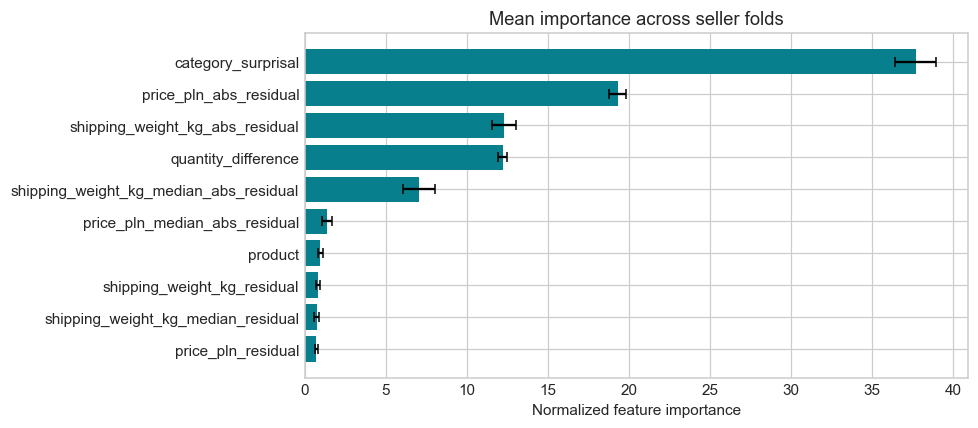

,id,title,target,prediction,product,error_score
6306,OFR_476814096,Noro portable wireless loudspeaker / standard / 1 pcs,1,0.0023,bluetooth speaker,0.9977
15287,OFR_395452994,Tens TV speaker bar / standard / 1 units,1,0.0025,soundbar,0.9975
15586,OFR_108502813,language worbook — 1 units — Mira F852,1,0.0026,english practice volume,0.9974
4615,OFR_520815217,wet shave applicator — 1-pack — Tenso A464,1,0.0028,shaving brush,0.9972
6676,OFR_584208408,TENSO D149: STANDARD RESISTANCE BAND (1-PACK),1,0.0028,elastic workout loop,0.9972
3782,OFR_138318936,running belt — 1 units — Aste A183,1,0.0031,jogging waist pouch,0.9969


In [11]:
importance = pd.DataFrame({'feature': feature_columns,
                           'mean_importance': np.mean(feature_importances, axis=0),
                           'std_importance': np.std(feature_importances, axis=0)}).sort_values('mean_importance', ascending=False)
display(importance.head(10).round(3))
top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top.feature, top.mean_importance, xerr=top.std_importance, color=TEAL, capsize=3)
ax.set(xlabel='Normalized feature importance', title='Mean importance across seller folds')
plt.tight_layout(); plt.show()
errors = train[['id', 'title', 'target']].copy()
errors['prediction'], errors['product'] = oof, F_oof['product']
errors['error_score'] = np.where(y == 1, 1 - oof, oof)
display(errors.sort_values('error_score', ascending=False).head(6).round(4))

,bin,rows,mean_probability,positive_fraction
0,0,13012,0.007,0.007
1,1,147,0.143,0.170
2,2,104,0.251,0.260
3,3,60,0.345,0.300
4,4,57,0.450,0.456
5,5,50,0.547,0.480
6,6,61,0.651,0.607
7,7,53,0.745,0.717
8,8,89,0.856,0.831
9,9,2367,0.989,0.997


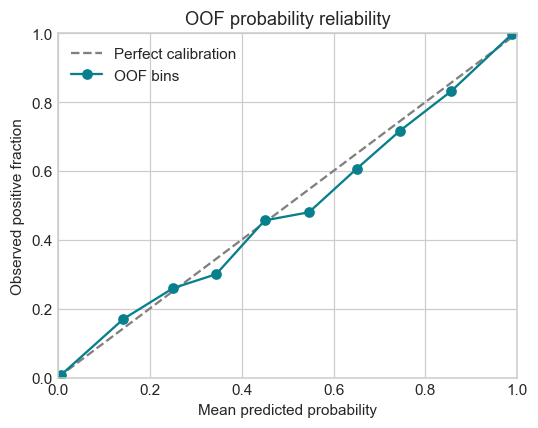

In [12]:
calibration = pd.DataFrame({'prediction': oof, 'target': y,
                            'bin': np.minimum((oof * 10).astype(int), 9)})
calibration = calibration.groupby('bin').agg(rows=('target', 'size'),
    mean_probability=('prediction', 'mean'), positive_fraction=('target', 'mean')).reset_index()
display(calibration.round(3))
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.plot(calibration.mean_probability, calibration.positive_fraction, 'o-', color=TEAL, label='OOF bins')
ax.set(xlabel='Mean predicted probability', ylabel='Observed positive fraction',
       title='OOF probability reliability', xlim=(0, 1), ylim=(0, 1))
ax.legend(); plt.tight_layout(); plt.show()
validation_complete = True

## 10. Final inference

The model specification, fitted folds and training-data validation are now complete. The prediction
files are loaded here for schema checks, ID alignment and inference. No statistics from these inputs
are fitted or used to revise the model. The submission uses the equal-weight mean of the five models.

In [13]:
assert validation_complete
test = pd.read_csv(DATA / 'test.csv')
sample = pd.read_csv(DATA / 'sample_submission.csv')
assert set(test.columns) == set(INPUT_COLUMNS) and 'target' not in test
assert test.id.notna().all() and test.id.is_unique and test.seller_id.notna().all()
assert set(train.id).isdisjoint(test.id)
assert set(train.seller_id).isdisjoint(test.seller_id)
assert sample.columns.tolist() == ['id', 'target'] and sample.id.tolist() == test.id.tolist()
for col in ['price_pln', 'shipping_weight_kg', 'pack_size']:
    assert np.isfinite(test[col].dropna()).all() and test[col].dropna().gt(0).all()
assert test.pack_size.dropna().mod(1).eq(0).all()

test_probability = np.zeros(len(test))
for model, reference in ensemble:
    values = model_input(listing_features(test, reference), feature_columns)
    test_probability += model.predict_proba(values)[:, 1] / len(ensemble)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()
submission = pd.DataFrame({'id': test.id, 'target': test_probability})
assert submission.id.tolist() == sample.id.tolist()

## 11. Save the submission, models and validation evidence

`submission.csv` contains probabilities in the required ID order. The output folder also contains
OOF predictions, metrics, calibration, feature importance and all five fitted model/reference pairs.
File hashes and package versions record the run inputs and model artifacts. Files are checked after writing.

In [14]:
OUT = ROOT / 'outputs/catalogue_submission'
OUT.mkdir(parents=True, exist_ok=True)
submission.to_csv(OUT / 'submission.csv', index=False)
written = pd.read_csv(OUT / 'submission.csv')
assert written.id.tolist() == sample.id.tolist()
assert np.isfinite(written.target).all() and written.target.between(0, 1).all()
pd.DataFrame({'id': train.id, 'seller_id': train.seller_id, 'target': y, 'prediction': oof,
              'fold': fold_id + 1, 'product': F_oof['product']}).to_csv(OUT / 'oof.csv', index=False)
importance.to_csv(OUT / 'feature_importance.csv', index=False)
calibration.to_csv(OUT / 'calibration.csv', index=False)
result = {'summary': summary, 'folds': scores.to_dict('records'), 'subgroups': subgroups}
(OUT / 'metrics.json').write_text(json.dumps(result, indent=2), encoding='utf-8')

def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

artifacts = []
for number, (model, reference) in enumerate(ensemble, 1):
    folder = OUT / 'models' / f'fold_{number}'
    folder.mkdir(parents=True, exist_ok=True)
    model.save_model(str(folder / 'classifier.cbm'))
    joblib.dump(reference, folder / 'reference.joblib')
    artifacts.append({'fold': number,
        'classifier': (folder / 'classifier.cbm').relative_to(OUT).as_posix(),
        'reference': (folder / 'reference.joblib').relative_to(OUT).as_posix(),
        'classifier_sha256': file_hash(folder / 'classifier.cbm'),
        'reference_sha256': file_hash(folder / 'reference.joblib')})
manifest = {'status': 'complete', 'feature_version': 'parsed-v2', 'pipeline_version': '1.1.0',
    'feature_columns': feature_columns, 'categorical_features': CATEGORICAL_FEATURES,
    'config': {'folds': OUTER_FOLDS, 'inner_folds': INNER_FOLDS, 'fold_seed': SEED,
               'model_seed': SEED, 'iterations': 450, 'depth': 5, 'learning_rate': .05,
               'l2_leaf_reg': 5, 'threads': 4, 'recover_products': True, 'median_reference': True},
    'fold_models': artifacts,
    'environment': {'python': platform.python_version(), **{name: version(name)
                    for name in ['numpy', 'pandas', 'scikit-learn', 'catboost', 'joblib']}},
    'input_sha256': {name: file_hash(DATA / name)
                     for name in ['train.csv', 'test.csv', 'sample_submission.csv']}}
(OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(f'Saved {len(submission):,} probabilities and {len(ensemble)} fold models to {OUT}')

Saved 10,000 probabilities and 5 fold models to C:\Users\adilk\Desktop\PJATK\KOLO NAUKOWE\outputs\catalogue_submission
